# Student Performance Analysis

## Project Objective
The objective of this project is to analyze student performance data and identify the key factors that influence academic performance.

This analysis explores the relationship between academic performance and factors such as study habits, attendance, demographics, and other available features.

In [6]:
import numpy as numpy
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline

In [7]:
import os
print("Your notebook is running in:")
print(os.getcwd())

print("\nFiles inside this folder:")
print(os.listdir('.'))


Your notebook is running in:
c:\Users\unnat\Student_Performance_Analysis\notebooks

Files inside this folder:
['student_performance_analysis.ipynb']


In [8]:

df = pd.read_csv("../data/StudentsPerformance.csv")
df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [9]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [10]:
df.shape

(1000, 8)

Obeservaton:
This data has 8 columns and 1000 rows
The dataset contains 1000 student records and 15 features.

In [11]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [12]:
df.columns.tolist()

['gender',
 'race/ethnicity',
 'parental level of education',
 'lunch',
 'test preparation course',
 'math score',
 'reading score',
 'writing score']

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [14]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [15]:
df.describe(include="all")

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [16]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [17]:
(df.isnull().sum() / len(df)) * 100

gender                         0.0
race/ethnicity                 0.0
parental level of education    0.0
lunch                          0.0
test preparation course        0.0
math score                     0.0
reading score                  0.0
writing score                  0.0
dtype: float64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
for column in df.columns:
    print(f"\n{column}")
    print(df[column].unique())


gender
['female' 'male']

race/ethnicity
['group B' 'group C' 'group A' 'group D' 'group E']

parental level of education
["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

lunch
['standard' 'free/reduced']

test preparation course
['none' 'completed']

math score
[ 72  69  90  47  76  71  88  40  64  38  58  65  78  50  18  46  54  66
  44  74  73  67  70  62  63  56  97  81  75  57  55  53  59  82  77  33
  52   0  79  39  45  60  61  41  49  30  80  42  27  43  68  85  98  87
  51  99  84  91  83  89  22 100  96  94  48  35  34  86  92  37  28  24
  26  95  36  29  32  93  19  23   8]

reading score
[ 72  90  95  57  78  83  43  64  60  54  52  81  53  75  89  32  42  58
  69  73  71  74  70  65  87  56  61  84  55  44  41  85  59  17  39  80
  37  63  51  49  26  68  45  47  86  34  79  66  67  91 100  76  77  82
  92  93  62  88  50  28  48  46  23  38  94  97  99  31  96  24  29  40]

writing score
[ 74  88  93  44  75 

In [20]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

## Dataset Description

| Column Name | Description | Data Type |
| :--- | :--- | :--- |
| **gender** | Male or female gender identity | object |
| **race/ethnicity** | Student's racial or ethnic group background (Group A–E) | object |
| **parental level of education** | Highest education level completed by student's parent(s) | object |
| **lunch** | Type of lunch received (standard or free/reduced) | object |
| **test preparation course** | Status of the test prep course (none or completed) | object |
| **math score** | Score obtained in Mathematics (0–100) | int64 |
| **reading score** | Score obtained in Reading (0–100) | int64 |
| **writing score** | Score obtained in Writing (0–100) | int64 |               


Demographic / Background
  gender
  race/ethnicity
  parental level of education


Support / Preparation Factors
 lunch
 test preparation course

Performance Metrics
 math score
 reading score
 writing score

## Feature Engineering

To evaluate overall student performance, an Average Score feature is created by calculating the mean of math, reading, and writing scores.

In [21]:
df["average score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

In [22]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


In [23]:
def performance_category(score):
    if score >= 80:
        return "High Performer"
    elif score >= 60:
        return "Average Performer"
    else:
        return "Low Performer"

In [24]:
df["performance category"] = df["average score"].apply(performance_category)

In [25]:
df["performance category"].value_counts()

performance category
Average Performer    517
Low Performer        285
High Performer       198
Name: count, dtype: int64

In [26]:
df[["math score", "reading score", "writing score", 
    "average score", "performance category"]].head()

,math score,reading score,writing score,average score,performance category
0,72,72,74,72.666667,Average Performer
1,69,90,88,82.333333,High Performer
2,90,95,93,92.666667,High Performer
3,47,57,44,49.333333,Low Performer
4,76,78,75,76.333333,Average Performer


## Univariate Analysis

### Overall Student Performance

This section analyzes the distribution and overall characteristics of student academic performance using the average score.

In [27]:
df["average score"].describe()

count    1000.000000
mean       67.770667
std        14.257326
min         9.000000
25%        58.333333
50%        68.333333
75%        77.666667
max       100.000000
Name: average score, dtype: float64

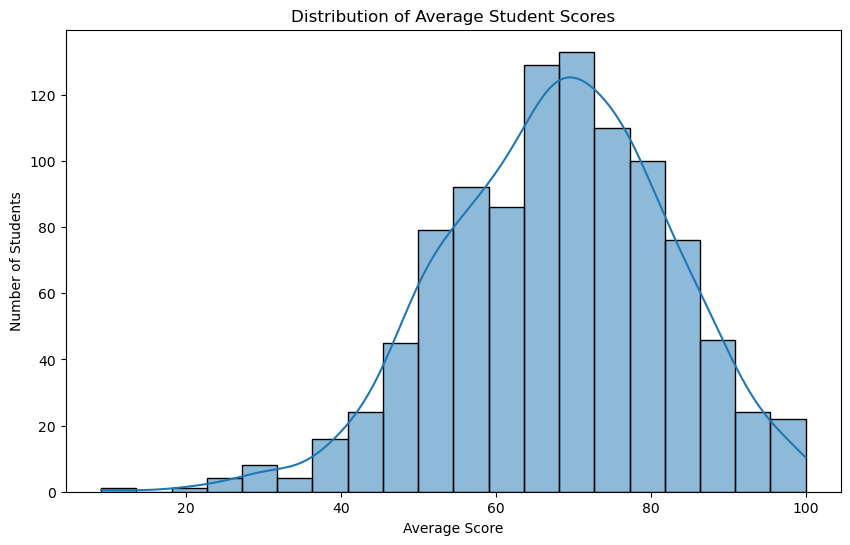

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="average score",
    bins=20,
    kde=True
)

plt.title("Distribution of Average Student Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")

plt.show()

Observations:
most of the students are between the 60-80
the curve is not bell shaped 

In [29]:
df["performance category"].value_counts()

performance category
Average Performer    517
Low Performer        285
High Performer       198
Name: count, dtype: int64

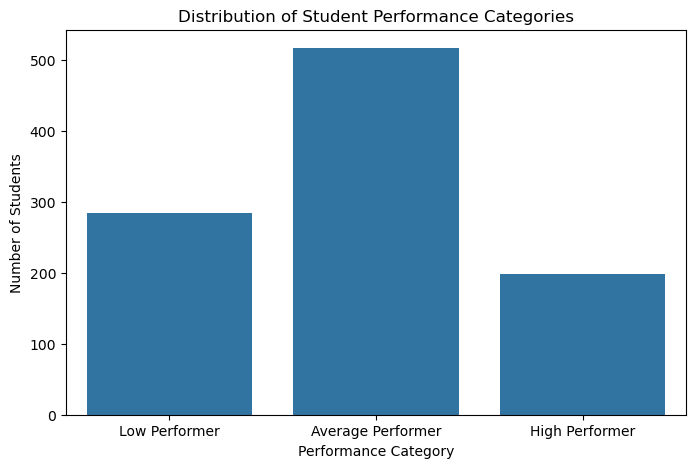

In [30]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="performance category",
    order=["Low Performer", "Average Performer", "High Performer"]
)

plt.title("Distribution of Student Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.show()

In [31]:
performance_percentage = (
    df["performance category"]
    .value_counts(normalize=True)
    * 100
)

performance_percentage

performance category
Average Performer    51.7
Low Performer        28.5
High Performer       19.8
Name: proportion, dtype: float64

### Key Observations

- The mean student score is approximately 67.77, while the median score is 68.33.
- More than half of the students (51.7%) are classified as Average Performers.
- 28.5% of students fall into the Low Performer category, while only 19.8% are High Performers.
- There is considerable variation in student performance, with average scores ranging from 9 to 100.

In [32]:
subject_averages = df[
    ["math score", "reading score", "writing score"]
].mean()

subject_averages

math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

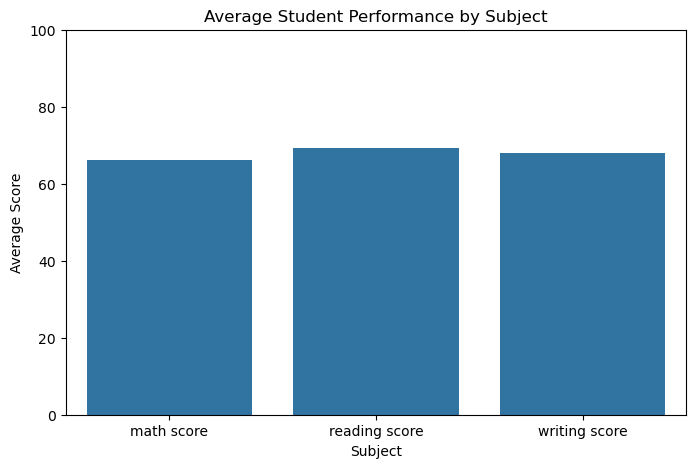

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=subject_averages.index,
    y=subject_averages.values
)

plt.title("Average Student Performance by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")

plt.ylim(0, 100)

plt.show()

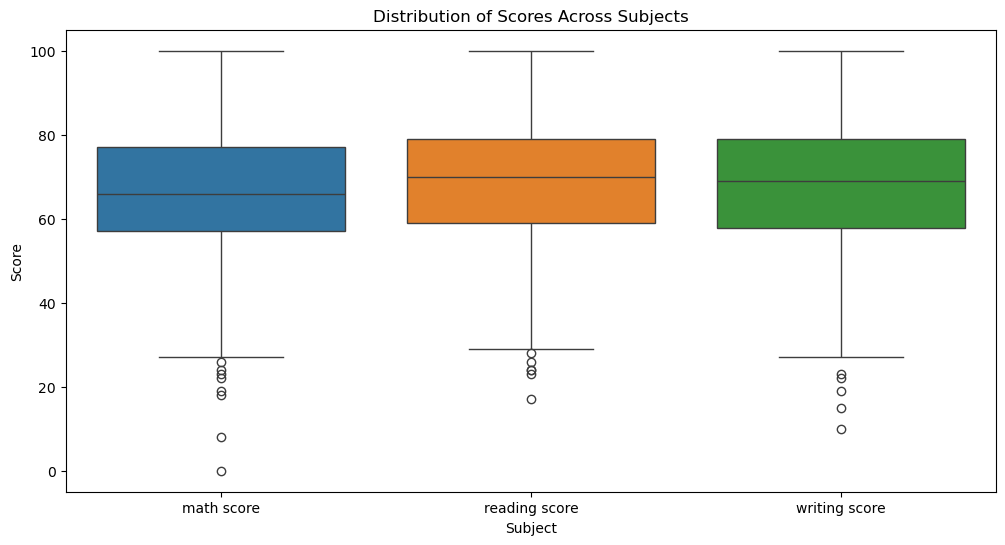

In [34]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[
        ["math score", "reading score", "writing score"]
    ]
)

plt.title("Distribution of Scores Across Subjects")
plt.xlabel("Subject")
plt.ylabel("Score")

plt.show()

### Key Observations

- Students achieved the highest average score in Reading (69.17).
- Writing had an average score of 68.05.
- Mathematics had the lowest average score (66.09).
- Overall, student performance is relatively similar across subjects, although Mathematics appears to be the comparatively weakest subject.

### Boxplot Observations

- Reading has the highest median score among the three subjects.
- The distribution and variability of scores appear relatively similar across all subjects.
- All three subjects contain several low-score potential outliers.
- Mathematics contains the most extreme low score, with at least one student scoring close to 0.
- These observations are retained because low scores represent valid student performance rather than confirmed data errors.

In [35]:
gender_performance = df.groupby("gender")[
    ["math score", "reading score", "writing score", "average score"]
].mean()

gender_performance

,math score,reading score,writing score,average score
gender,,,,
female,63.633205,72.608108,72.467181,69.569498
male,68.728216,65.473029,63.311203,65.837483


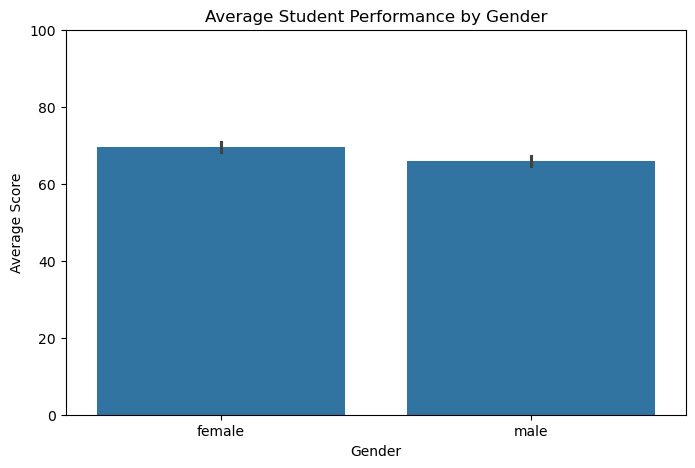

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="gender",
    y="average score"
)

plt.title("Average Student Performance by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")

plt.ylim(0, 100)

plt.show()

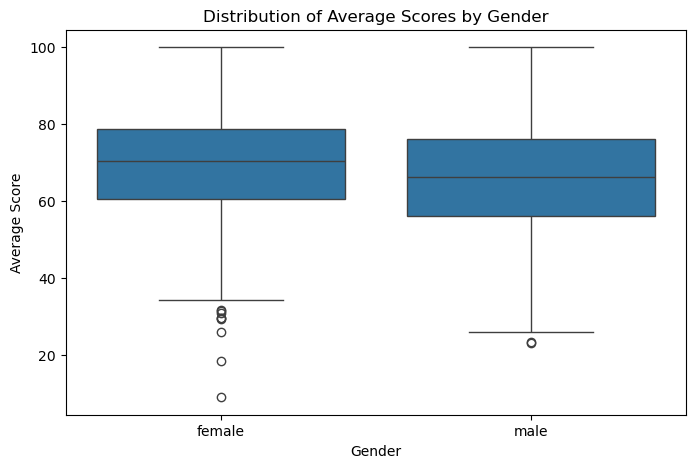

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="gender",
    y="average score"
)

plt.title("Distribution of Average Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")

plt.show()

In [38]:
gender_performance = df.groupby("gender")[
    ["math score", "reading score", "writing score", "average score"]
].mean().round(2)

gender_performance

,math score,reading score,writing score,average score
gender,,,,
female,63.63,72.61,72.47,69.57
male,68.73,65.47,63.31,65.84


In [39]:
gender_performance.loc["female"] - gender_performance.loc["male"]

math score      -5.10
reading score    7.14
writing score    9.16
average score    3.73
dtype: float64

### Gender-Based Performance Analysis

- Female students achieved a higher overall average score in this dataset.
- Performance differences varied by subject, with each gender performing better in some subjects.
- These results describe differences in this dataset and do not establish that gender causes differences in academic performance.

In [40]:
df.groupby("test preparation course")[
    ["math score", "reading score", "writing score", "average score"]
].mean().round(2)

,math score,reading score,writing score,average score
test preparation course,,,,
completed,69.70,73.89,74.42,72.67
none,64.08,66.53,64.50,65.04


### Test Preparation Course and Academic Performance — Key Findings

- Students who completed the test preparation course achieved a higher overall average score (72.67) than students who did not complete it (65.04).
- The overall average-score difference between the two groups was 7.63 points.
- Writing showed the largest difference between the groups (9.92 points), followed by Reading (7.36 points) and Mathematics (5.62 points).
- The results indicate a positive association between test preparation course completion and academic performance in this dataset.
- This analysis does not establish causation because other factors may also influence student scores.

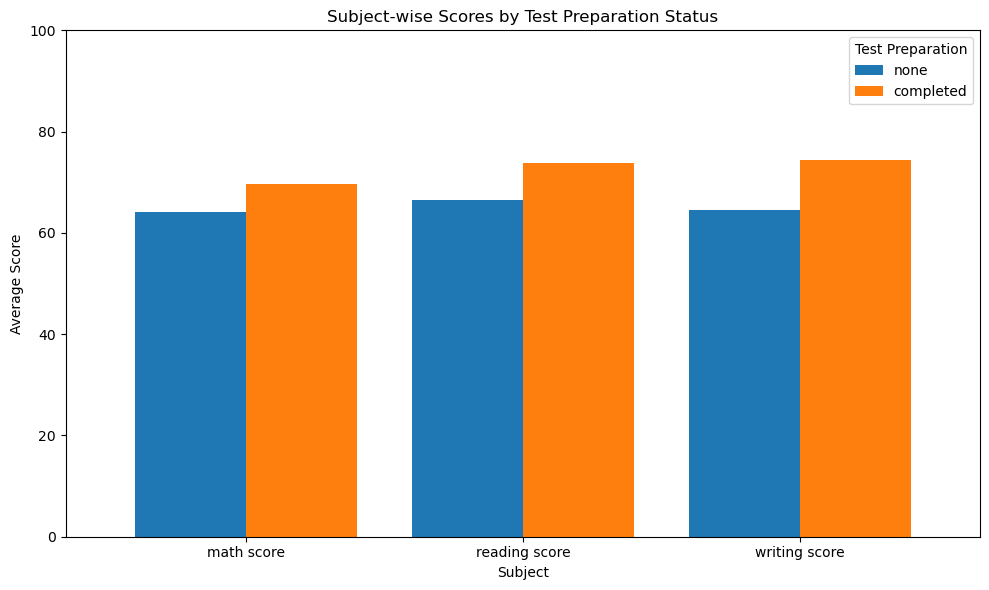

In [41]:
subject_scores = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean()

subject_scores = subject_scores.loc[["none", "completed"]]

subject_scores.T.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Subject-wise Scores by Test Preparation Status")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Test Preparation")
plt.tight_layout()
plt.show()

In [42]:
parent_education = df.groupby(
    "parental level of education"
)["average score"].mean().sort_values(ascending=False)

parent_education.round(2)

parental level of education
master's degree       73.60
bachelor's degree     71.92
associate's degree    69.57
some college          68.48
some high school      65.11
high school           63.10
Name: average score, dtype: float64

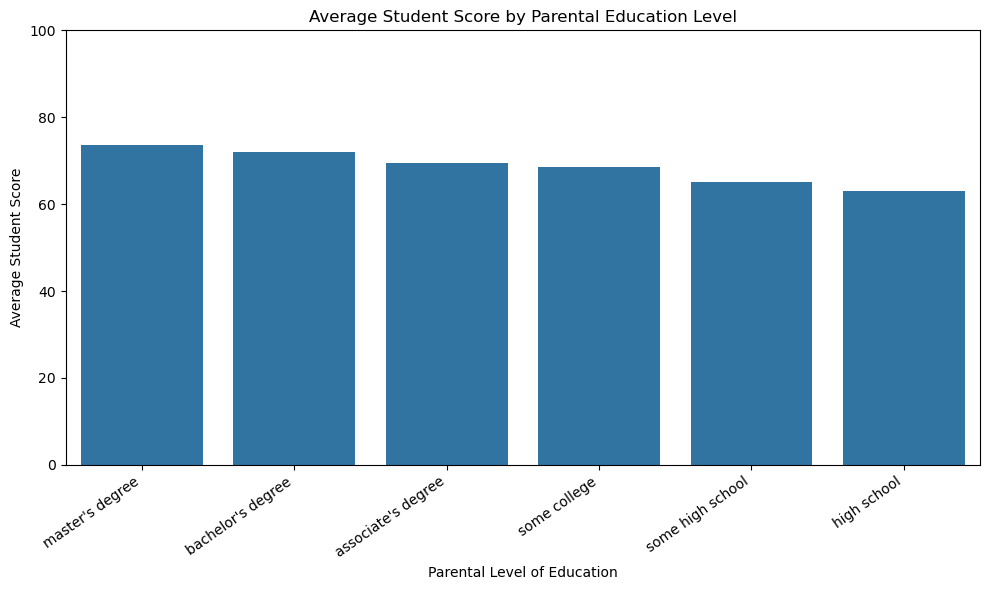

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=parent_education.index,
    y=parent_education.values
)

plt.title("Average Student Score by Parental Education Level")
plt.xlabel("Parental Level of Education")
plt.ylabel("Average Student Score")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Parental Education and Academic Performance — Key Findings

- Students whose parents had a master's degree achieved the highest average score (73.60).
- Students whose parents had a high school education had the lowest average score (63.10).
- The difference between these two categories was 10.50 points.
- The results suggest an association between parental education level and student performance in this dataset.
- The relationship is not perfectly linear, and the analysis does not establish causation.

In [44]:
lunch_performance = df.groupby("lunch")[
    ["math score", "reading score", "writing score", "average score"]
].mean().round(2)

lunch_performance

,math score,reading score,writing score,average score
lunch,,,,
free/reduced,58.92,64.65,63.02,62.20
standard,70.03,71.65,70.82,70.84


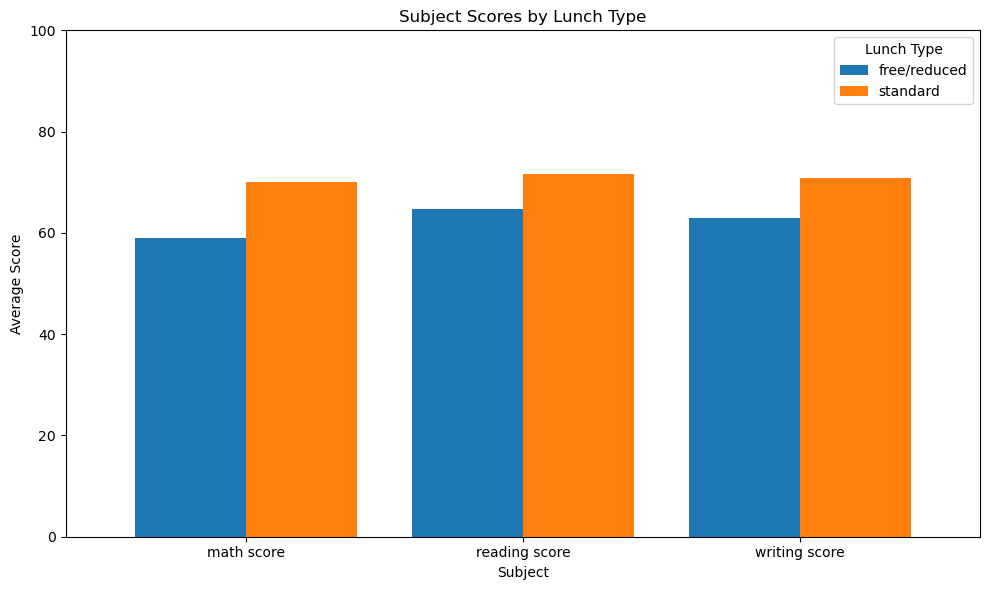

In [45]:
lunch_subject_scores = df.groupby("lunch")[
    ["math score", "reading score", "writing score"]
].mean()

lunch_subject_scores = lunch_subject_scores.loc[
    ["free/reduced", "standard"]
]

lunch_subject_scores.T.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Subject Scores by Lunch Type")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Lunch Type")
plt.tight_layout()
plt.show()

### Lunch Type and Academic Performance — Key Findings

- Students in the standard-lunch group achieved an overall average score of 70.84, compared with 62.20 for the free/reduced-lunch group.
- The difference in overall average scores was 8.64 points.
- Mathematics showed the largest score difference (11.11 points), followed by Writing (7.80 points) and Reading (7.00 points).
- These results indicate an association between lunch category and academic performance in this dataset.
- Further analysis would be needed to investigate other factors that may explain these differences. The findings do not establish causation.

In [46]:
ethnicity_performance = df.groupby("race/ethnicity")[
    ["math score", "reading score", "writing score", "average score"]
].mean().round(2)

ethnicity_performance.sort_values(
    by="average score",
    ascending=False
)

,math score,reading score,writing score,average score
race/ethnicity,,,,
group E,73.82,73.03,71.41,72.75
group D,67.36,70.03,70.15,69.18
group C,64.46,69.10,67.83,67.13
group B,63.45,67.35,65.60,65.47
group A,61.63,64.67,62.67,62.99


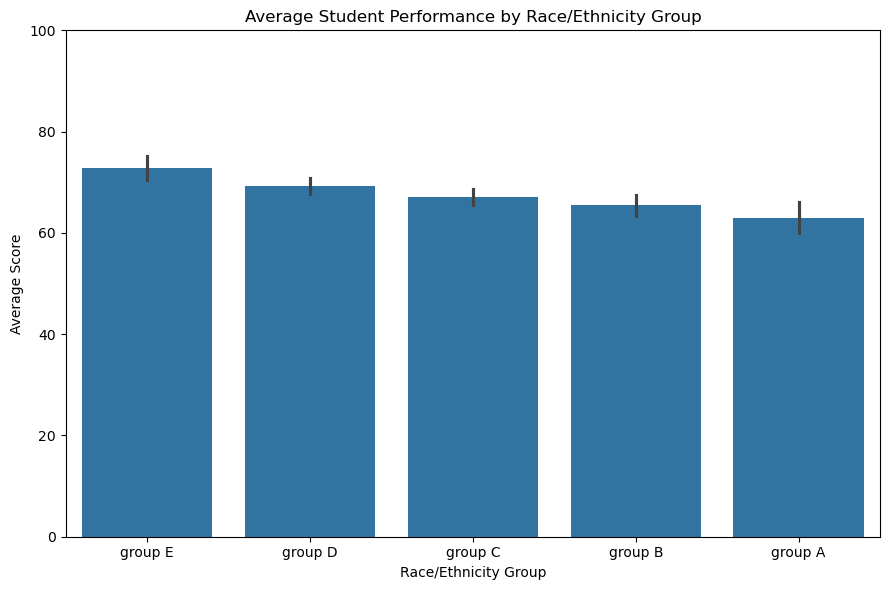

In [47]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df,
    x="race/ethnicity",
    y="average score",
    order=["group E", "group D", "group C", "group B", "group A"]
)

plt.title("Average Student Performance by Race/Ethnicity Group")
plt.xlabel("Race/Ethnicity Group")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Race/Ethnicity Group Analysis — Key Findings

- Group E achieved the highest overall average score (72.75), while Group A had the lowest (62.99).
- The difference between the highest and lowest group averages was 9.76 points.
- Group E had the highest average score in Mathematics, Reading, and Writing among the groups in this dataset.
- These results describe observed differences between groups. They do not establish causation or explain the underlying reasons for the differences.

In [48]:
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

correlation_matrix = df[score_columns].corr()

correlation_matrix

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


### Correlation Analysis — Key Findings

- Reading and Writing have the strongest positive correlation, approximately 0.955.
- Math and Reading have a strong positive correlation of approximately 0.818.
- Math and Writing also have a strong positive correlation of approximately 0.803.
- All three pairs of subjects show strong positive linear relationships.
- These relationships suggest that academic performance across subjects tends to move together, but correlation alone does not establish causation.

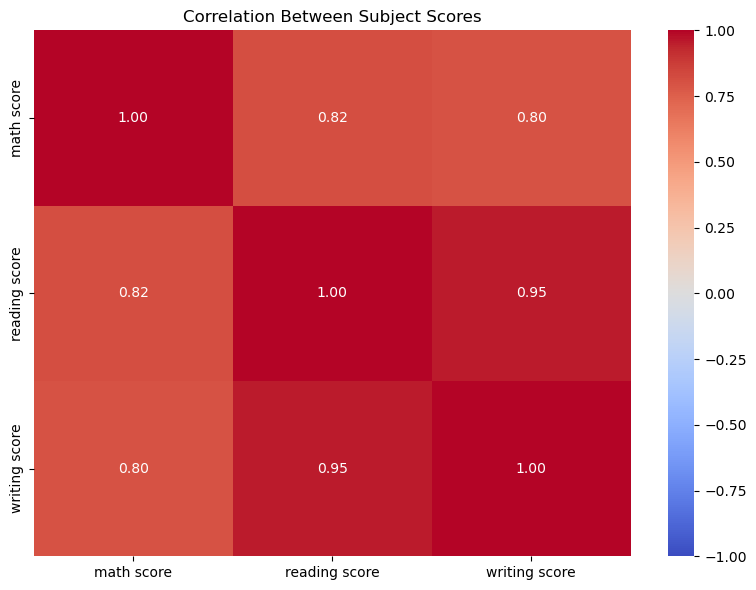

In [49]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Subject Scores")
plt.tight_layout()
plt.show()

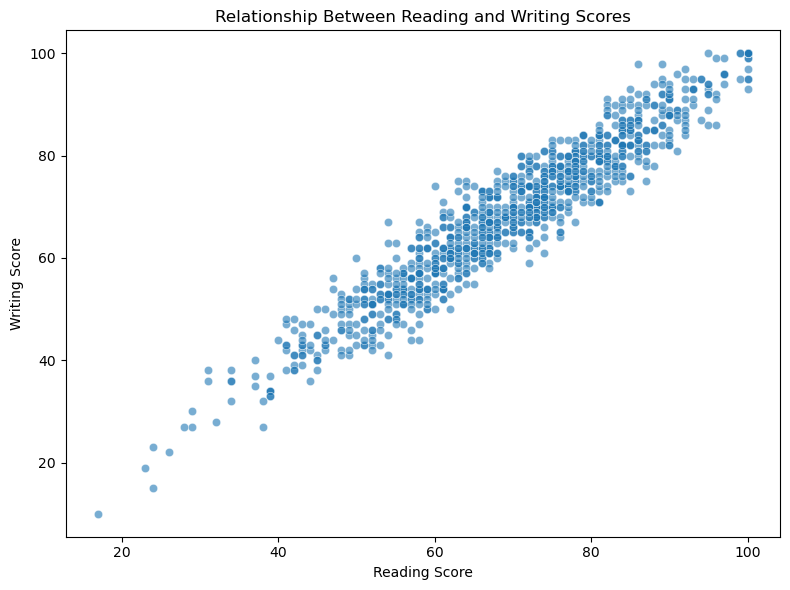

In [50]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="reading score",
    y="writing score",
    alpha=0.6
)

plt.title("Relationship Between Reading and Writing Scores")
plt.xlabel("Reading Score")
plt.ylabel("Writing Score")
plt.tight_layout()
plt.show()

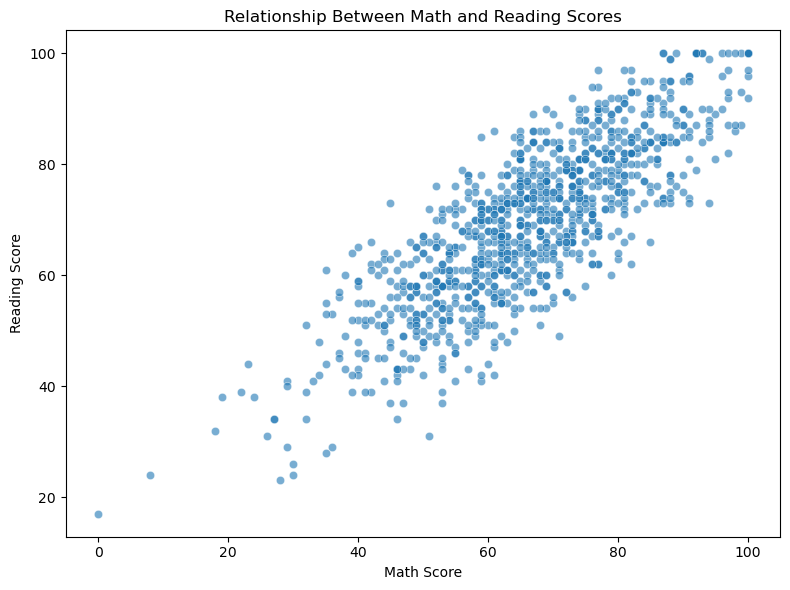

In [51]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="math score",
    y="reading score",
    alpha=0.6
)

plt.title("Relationship Between Math and Reading Scores")
plt.xlabel("Math Score")
plt.ylabel("Reading Score")
plt.tight_layout()
plt.show()

## Final Conclusion

The objective of this project was to explore student academic performance and examine its relationships with demographic, educational, and preparation-related factors.

### Key Findings

1. **Overall performance:** The dataset contains 1,000 student records. The mean average score was 67.77, with a median of 68.33.

2. **Subject comparison:** Reading had the highest mean score (69.17), followed by Writing (68.05) and Mathematics (66.09).

3. **Test preparation:** Students who completed the test preparation course had a higher mean average score (72.67) than students who did not complete it (65.04).

4. **Parental education:** The highest average score was observed among students whose parents had a master's degree (73.60), while the high school category had the lowest average (63.10).

5. **Lunch category:** Students in the standard-lunch group had a higher mean average score (70.84) than those in the free/reduced-lunch group (62.20).

6. **Gender:** Female students had a higher overall average in the comparisons conducted, although the subject-level differences varied.

7. **Race/ethnicity groups:** Group E had the highest overall average (72.75), while Group A had the lowest (62.99).

8. **Subject correlations:** Reading and Writing had the strongest positive correlation (approximately 0.955). Math was also strongly positively correlated with Reading (0.818) and Writing (0.803).

### Limitations

- The analysis identifies associations and differences, not causal relationships.
- The dataset does not include variables such as attendance, study hours, or previous academic performance.
- The low, average, and high performance categories use thresholds selected for this project and should not be interpreted as official academic classifications.
- Further statistical analysis would be needed to assess whether observed group differences are statistically significant.

### Conclusion

The analysis identifies several patterns in student performance, particularly the relationships between test preparation, lunch category, parental education, and subject scores. These findings provide a starting point for further investigation into factors associated with academic outcomes.